# Python for Data Analysis: NumPy, Pandas and Matplotlib Basics

### How the three fit together
```
   Raw data  ──►  Pandas (clean, filter, group)  ──►  Matplotlib (visualize)
                        ▲
                        │ built on top of
                     NumPy (fast numerical arrays)
```

> **Tip:** Run each cell with **Shift + Enter**. Everything here runs on its own. No external files are needed.

In [8]:
# Standard import conventions (used by almost everyone in the community)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version     :", np.__version__)
print("Pandas version    :", pd.__version__)
import matplotlib; print("Matplotlib version:", matplotlib.__version__)

NumPy version     : 2.0.2
Pandas version    : 2.3.3
Matplotlib version: 3.9.4


---
# Part 1: NumPy (Numerical Python)

## 1.1 Why NumPy?
A Python `list` can hold anything, but it is **slow** for math, and you cannot do math on the whole list at once.
A NumPy **array** (`ndarray`) has these properties:
- All elements share **one data type**, which keeps them compact in memory.
- **Vectorized** operations apply math to every element at once, with no loops.
- It is **much faster** because the work runs in optimized C code.

In [9]:
# Python list vs NumPy array
py_list = [1, 2, 3, 4, 5]
np_arr  = np.array([1, 2, 3, 4, 5])

print("List * 2  :", py_list * 2)     # repeats the list!
print("Array * 2 :", np_arr * 2)      # multiplies every element

List * 2  : [1, 2, 3, 4, 5, 1, 2, 3, 4, 5]
Array * 2 : [ 2  4  6  8 10]


In [10]:
# Speed comparison: sum of squares of 1 million numbers
import time
n = 1_000_000
lst = list(range(n))
arr = np.arange(n)

t0 = time.perf_counter(); s1 = sum(x**2 for x in lst); t1 = time.perf_counter()
s2 = (arr**2).sum();                                     t2 = time.perf_counter()

print(f"Python list : {t1-t0:.4f} s")
print(f"NumPy array : {t2-t1:.4f} s  ->  about {(t1-t0)/(t2-t1):.0f}x faster")

Python list : 0.1092 s
NumPy array : 0.0006 s  ->  about 191x faster


## 1.2 Creating arrays

In [12]:
a = np.array([10, 20, 30])                 # from a list
b = np.array([[1, 2, 3], [4, 5, 6]])       # 2-D (matrix) from nested lists
print(b)

print("zeros     :\n", np.zeros((2, 3)))
print("ones      :\n", np.ones((2, 2)))
print("arange    :", np.arange(0, 10, 2))      # start, stop (excluded), step
print("linspace  :", np.linspace(0, 1, 5))     # 5 evenly spaced points from 0 to 1
print("full      :\n", np.full((2, 2), 7))

[[1 2 3]
 [4 5 6]]
zeros     :
 [[0. 0. 0.]
 [0. 0. 0.]]
ones      :
 [[1. 1.]
 [1. 1.]]
arange    : [0 2 4 6 8]
linspace  : [0.   0.25 0.5  0.75 1.  ]
full      :
 [[7 7]
 [7 7]]


## 1.3 Array attributes
Every array knows its **shape**, number of **dimensions**, **size** and **data type**.

In [5]:
m = np.array([[1, 2, 3],
              [4, 5, 6]])

print("shape :", m.shape)   # (rows, columns)
print("ndim  :", m.ndim)    # number of dimensions
print("size  :", m.size)    # total number of elements
print("dtype :", m.dtype)   # data type of elements

f = np.array([1, 2, 3], dtype=float)
print("float array:", f, f.dtype)

shape : (2, 3)
ndim  : 2
size  : 6
dtype : int64
float array: [1. 2. 3.] float64


## 1.4 Indexing and slicing
- Indexing starts at **0**.
- Slicing uses `start:stop:step`. The `stop` position is **excluded**.
- In 2-D arrays, use `arr[row, column]`.

In [6]:
x = np.arange(10, 20)       # [10 11 ... 19]
print("x          :", x)
print("x[0]       :", x[0])
print("x[-1]      :", x[-1])     # last element
print("x[2:5]     :", x[2:5])
print("x[::2]     :", x[::2])    # every 2nd element
print("x[::-1]    :", x[::-1])   # reversed

x          : [10 11 12 13 14 15 16 17 18 19]
x[0]       : 10
x[-1]      : 19
x[2:5]     : [12 13 14]
x[::2]     : [10 12 14 16 18]
x[::-1]    : [19 18 17 16 15 14 13 12 11 10]


In [7]:
grid = np.arange(1, 13).reshape(3, 4)
print(grid, "\n")
print("grid[1, 2]   :", grid[1, 2])       # row 1, column 2
print("grid[0]      :", grid[0])          # first row
print("grid[:, 1]   :", grid[:, 1])       # second column
print("grid[:2, 2:] :\n", grid[:2, 2:])   # top-right block

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]] 

grid[1, 2]   : 7
grid[0]      : [1 2 3 4]
grid[:, 1]   : [ 2  6 10]
grid[:2, 2:] :
 [[3 4]
 [7 8]]


## 1.5 Boolean indexing (filtering)
A condition on an array returns an array of `True`/`False` values. Use it to **select** elements.

In [8]:
scores = np.array([45, 82, 67, 91, 38, 74, 59])

mask = scores >= 60
print("mask           :", mask)
print("passing scores :", scores[mask])
print("between 50-80  :", scores[(scores > 50) & (scores < 80)])   # use & and |, with brackets
print("count passing  :", mask.sum())

# np.where: if-else on every element
print("labels         :", np.where(scores >= 60, "Pass", "Fail"))

mask           : [False  True  True  True False  True False]
passing scores : [82 67 91 74]
between 50-80  : [67 74 59]
count passing  : 4
labels         : ['Fail' 'Pass' 'Pass' 'Pass' 'Fail' 'Pass' 'Fail']


## 1.6 Vectorized math and broadcasting
Operations work **element by element**. With **broadcasting**, NumPy stretches smaller arrays to fit larger ones automatically.

In [9]:
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])

print("a + b   :", a + b)
print("a * b   :", a * b)
print("a ** 2  :", a ** 2)
print("sqrt(b) :", np.sqrt(b))
print("a + 100 :", a + 100)        # scalar broadcast to every element

a + b   : [11 22 33]
a * b   : [10 40 90]
a ** 2  : [1 4 9]
sqrt(b) : [3.16227766 4.47213595 5.47722558]
a + 100 : [101 102 103]


In [13]:
# Broadcasting a row across a matrix
matrix = np.array([[1, 2, 3],
                   [4, 5, 6],
                   [7, 8, 9]])
row = np.array([100, 200, 300])

print(matrix + row)   # row is added to EACH row of matrix

# Practical example: convert temperatures C -> F for a whole week at once
celsius = np.array([18.5, 21.0, 23.4, 19.8, 25.1])
print("Fahrenheit:", celsius * 9/5 + 32)

[[101 202 303]
 [104 205 306]
 [107 208 309]]
Fahrenheit: [65.3  69.8  74.12 67.64 77.18]


## 1.7 Aggregations (statistics)
Use `axis=0` to work **down the columns** and `axis=1` to work **across the rows**.

In [11]:
data = np.array([[3, 7, 2],
                 [8, 1, 5]])

print("sum      :", data.sum())
print("mean     :", data.mean())
print("max/min  :", data.max(), data.min())
print("std      :", data.std().round(3))
print("argmax   :", data.argmax())           # position of the max (flattened)
print("sum axis=0 (per column):", data.sum(axis=0))
print("sum axis=1 (per row)   :", data.sum(axis=1))

sum      : 26
mean     : 4.333333333333333
max/min  : 8 1
std      : 2.56
argmax   : 3
sum axis=0 (per column): [11  8  7]
sum axis=1 (per row)   : [12 14]


## 1.8 Reshaping and combining

In [ ]:
v = np.arange(1, 7)
print("original      :", v)
print("reshape(2,3)  :\n", v.reshape(2, 3))
print("reshape(3,-1) :\n", v.reshape(3, -1))   # -1 = 'figure it out how many columns are needed based on the number of elements'
print("transpose     :\n", v.reshape(2, 3).T) # turn rows into columns and columns into rows
print("flatten       :", v.reshape(2, 3).flatten())

p = np.array([1, 2]); q = np.array([3, 4])
print("concatenate   :", np.concatenate([p, q]))

original      : [1 2 3 4 5 6]
reshape(2,3)  :
 [[1 2 3]
 [4 5 6]]
reshape(3,-1) :
 [[1 2]
 [3 4]
 [5 6]]
transpose     :
 [[1 4]
 [2 5]
 [3 6]]
flatten       : [1 2 3 4 5 6]
concatenate   : [1 2 3 4]


## 1.9 Random numbers
Set a **seed** so you get the same "random" results every time. This makes your work reproducible.

In [6]:
rng = np.random.default_rng(seed=42)       # modern recommended way

print("random ints  :", rng.integers(1, 7, size=10))       # dice rolls
print("uniform 0-1  :", rng.random(3).round(3))
normal = rng.normal(loc=170, scale=10, size=1000)           # heights in cm
print("normal mean  :", normal.mean().round(2), " std:", normal.std().round(2))


random ints  : [1 5 4 3 3 6 1 5 2 1]
uniform 0-1  : [0.976 0.761 0.786]
normal mean  : 169.74  std: 9.86


### NumPy key takeaways
- `np.array` gives fast arrays where every element has the same type.
- Vectorized math replaces most loops.
- Boolean masks are a powerful way to filter data.
- `axis=0` works per column and `axis=1` works per row.

---
# Part 2: Pandas

## 2.1 Core data structures
| Structure | Think of it as | Dimensions |
|---|---|---|
| `Series` | One column with labels (an index) | 1-D |
| `DataFrame` | A whole table (like an Excel sheet) | 2-D |

A DataFrame is a set of Series that share the same index.

In [14]:
# Series: values + index labels
s = pd.Series([250, 310, 180], index=["Mon", "Tue", "Wed"], name="sales")
print(s)
print("\nTuesday sales:", s["Tue"])
print("Mean:", s.mean())

Mon    250
Tue    310
Wed    180
Name: sales, dtype: int64

Tuesday sales: 310
Mean: 246.66666666666666


In [14]:
# DataFrame from a dictionary (keys become column names)
df_small = pd.DataFrame({
    "name":   ["Asha", "Ben", "Carla", "Dev"],
    "age":    [28, 35, 42, 23],
    "city":   ["Chennai", "Detroit", "Cologne", "Chennai"],
    "salary": [52000, 68000, 81000, 45000],
})
df_small

,name,age,city,salary
0,Asha,28,Chennai,52000
1,Ben,35,Detroit,68000
2,Carla,42,Cologne,81000
3,Dev,23,Chennai,45000


## 2.2 A realistic dataset
We generate a small **sales dataset** here. In real work you would usually load data from a file:
```python
df = pd.read_csv("sales.csv")        # also: pd.read_excel, pd.read_json, pd.read_sql ...
```

In [20]:
rng = np.random.default_rng(7)
n = 200
df = pd.DataFrame({
    "date":     pd.date_range("2025-01-01", periods=n, freq="D"),
    "region":   rng.choice(["North", "South", "East", "West"], size=n),
    "product":  rng.choice(["Laptop", "Phone", "Tablet"], size=n, p=[0.3, 0.5, 0.2]),
    "units":    rng.integers(1, 20, size=n),
    "price":    rng.choice([1200, 800, 450], size=n),
})

df["revenue"] = df["units"] * df["price"]

# Add a few missing values on purpose (real data is messy)
df.loc[rng.choice(n, 8, replace=False), "units"] = np.nan

df.to_csv("sales.csv", index=False)    # save it ...
df = pd.read_csv("sales.csv", parse_dates=["date"])   # ... and load it back, like real life
df.head(10)

,date,region,product,units,price,revenue
0,2025-01-01,West,Tablet,6.0,450,2700
1,2025-01-02,East,Phone,13.0,1200,15600
2,2025-01-03,East,Phone,4.0,450,1800
3,2025-01-04,West,Phone,4.0,450,1800
4,2025-01-05,East,Tablet,17.0,800,13600
5,2025-01-06,West,Phone,15.0,1200,18000
6,2025-01-07,West,Phone,12.0,1200,14400
7,2025-01-08,North,Phone,15.0,800,12000
8,2025-01-09,North,Phone,7.0,1200,8400
9,2025-01-10,South,Phone,14.0,1200,16800


## 2.3 First look at the data
These are the first commands to run on any new dataset.

In [17]:
print("Shape (rows, cols):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:\n", df.dtypes)

Shape (rows, cols): (200, 6)

Columns: ['date', 'region', 'product', 'units', 'price', 'revenue']

Data types:
 date       datetime64[us]
region                str
product               str
units             float64
price               int64
revenue             int64
dtype: object


In [18]:
df.info()      # columns, types, non-null counts, memory

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     200 non-null    datetime64[us]
 1   region   200 non-null    str           
 2   product  200 non-null    str           
 3   units    192 non-null    float64       
 4   price    200 non-null    int64         
 5   revenue  200 non-null    int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(2)
memory usage: 11.5 KB


In [19]:
df.describe()  # summary statistics for numeric columns

,date,units,price,revenue
count,200,192.000000,200.000000,200.000000
mean,2025-04-10 12:00:00,10.234375,804.750000,8202.750000
min,2025-01-01 00:00:00,1.000000,450.000000,450.000000
25%,2025-02-19 18:00:00,5.000000,450.000000,3600.000000
50%,2025-04-10 12:00:00,10.000000,800.000000,7200.000000
75%,2025-05-30 06:00:00,15.250000,1200.000000,12000.000000
max,2025-07-19 00:00:00,19.000000,1200.000000,22800.000000
std,NaN,5.682919,300.443454,5735.659849


In [20]:
print(df["region"].value_counts())     # frequency of each category
print("\nUnique products:", df["product"].unique())

region
East     53
West     52
North    48
South    47
Name: count, dtype: int64

Unique products: <ArrowStringArray>
['Tablet', 'Phone', 'Laptop']
Length: 3, dtype: str


## 2.4 Selecting data
| Syntax | Selects |
|---|---|
| `df["col"]` | One column (Series) |
| `df[["a", "b"]]` | Several columns (DataFrame) |
| `df.loc[rows, cols]` | By **label** |
| `df.iloc[rows, cols]` | By **integer position** |

In [21]:
df[["date", "product", "revenue"]].head(3)

,date,product,revenue
0,2025-01-01,Tablet,2700
1,2025-01-02,Phone,15600
2,2025-01-03,Phone,1800


In [21]:
print("loc  (labels)   :\n", df.loc[0:3, ["region", "units"]], "\n")   # loc includes the end label
print("iloc (positions):\n", df.iloc[0:2, 1:3])                     # iloc excludes the end position

loc  (labels)   :
   region  units
0   West    6.0
1   East   13.0
2   East    4.0
3   West    4.0 

iloc (positions):
   region product
0   West  Tablet
1   East   Phone


## 2.5 Filtering rows
This works the same way as NumPy boolean indexing.

In [22]:
big_laptop_sales = df[(df["product"] == "Laptop") & (df["revenue"] > 15000)]
big_laptop_sales.head()

,date,region,product,units,price,revenue
28,2025-01-29,South,Laptop,15.0,1200,18000
85,2025-03-27,East,Laptop,14.0,1200,16800
96,2025-04-07,East,Laptop,13.0,1200,15600
134,2025-05-15,West,Laptop,18.0,1200,21600
146,2025-05-27,North,Laptop,19.0,1200,22800


In [24]:
# .isin() for multiple values, .query() for readable filters
print(df[df["region"].isin(["North", "East"])].shape)
df.query("product == 'Phone' and units >= 18").head()

(101, 6)


,date,region,product,units,price,revenue
24,2025-01-25,East,Phone,19.0,450,8550
40,2025-02-10,South,Phone,18.0,1200,21600
41,2025-02-11,North,Phone,19.0,800,15200
64,2025-03-06,West,Phone,18.0,450,8100
95,2025-04-06,East,Phone,18.0,450,8100


## 2.6 Adding and changing columns

In [25]:
df["month"]      = df["date"].dt.month_name()                 # date features via .dt
df["high_value"] = df["revenue"] > 10000                      # boolean column
df["size"]       = pd.cut(df["units"], bins=[0, 5, 12, 20],
                          labels=["Small", "Medium", "Large"])  # binning
df["region_code"] = df["region"].str[0]                       # string methods via .str
df.head()

,date,region,product,units,price,revenue,month,high_value,size,region_code
0,2025-01-01,West,Tablet,6.0,450,2700,January,False,Medium,W
1,2025-01-02,East,Phone,13.0,1200,15600,January,True,Large,E
2,2025-01-03,East,Phone,4.0,450,1800,January,False,Small,E
3,2025-01-04,West,Phone,4.0,450,1800,January,False,Small,W
4,2025-01-05,East,Tablet,17.0,800,13600,January,True,Large,E


## 2.7 Handling missing data

In [26]:
print("Missing values per column:\n", df.isna().sum())

Missing values per column:
 date           0
region         0
product        0
units          8
price          0
revenue        0
month          0
high_value     0
size           8
region_code    0
dtype: int64


In [23]:
# Option 1: drop rows that have missing values
print("Rows before / after dropna:", len(df), "/", len(df.dropna()))

# Option 2: fill them (here with the median of the column)
df["units"] = df["units"].fillna(df["units"].median())
df["revenue"] = df["units"] * df["price"]        # recompute after filling
print("Missing units now:", df["units"].isna().sum())

Rows before / after dropna: 200 / 192
Missing units now: 0


## 2.8 Sorting

In [24]:
df.sort_values("revenue", ascending=False).head(5)

,date,region,product,units,price,revenue
146,2025-05-27,North,Laptop,19.0,1200,22800.0
178,2025-06-28,North,Phone,19.0,1200,22800.0
186,2025-07-06,West,Laptop,19.0,1200,22800.0
49,2025-02-19,North,Tablet,18.0,1200,21600.0
116,2025-04-27,East,Tablet,18.0,1200,21600.0


## 2.9 GroupBy: split, apply, combine
This is the pandas version of SQL `GROUP BY`, and it works much like an Excel pivot table.

In [29]:
# Total revenue per region
df.groupby("region")["revenue"].sum().sort_values(ascending=False)

region
West     460800.0
East     460500.0
North    400550.0
South    319850.0
Name: revenue, dtype: float64

In [30]:
# Several statistics at once
df.groupby("product").agg(
    total_revenue=("revenue", "sum"),
    avg_units=("units", "mean"),
    num_orders=("revenue", "count"),
).round(1)

,total_revenue,avg_units,num_orders
product,,,
Laptop,432400.0,9.4,56
Phone,810950.0,10.2,100
Tablet,398350.0,11.4,44


In [31]:
# Pivot table: regions as rows, products as columns
pd.pivot_table(df, values="revenue", index="region", columns="product", aggfunc="sum")

product,Laptop,Phone,Tablet
region,,,
East,94400.0,207300.0,158800.0
North,98050.0,197000.0,105500.0
South,98800.0,157300.0,63750.0
West,141150.0,249350.0,70300.0


## 2.10 Combining tables (merge = SQL join)

In [32]:
managers = pd.DataFrame({
    "region":  ["North", "South", "East", "West"],
    "manager": ["Priya", "Tom", "Lena", "Marco"],
})
region_rev = df.groupby("region", as_index=False)["revenue"].sum()
pd.merge(region_rev, managers, on="region", how="left")

,region,revenue,manager
0,East,460500.0,Lena
1,North,400550.0,Priya
2,South,319850.0,Tom
3,West,460800.0,Marco


## 2.11 Applying custom functions

In [33]:
def rating(rev):
    if rev > 15000: return "A"
    if rev > 5000:  return "B"
    return "C"

df["rating"] = df["revenue"].apply(rating)
df[["revenue", "rating"]].head()

,revenue,rating
0,2700.0,C
1,15600.0,A
2,1800.0,C
3,1800.0,C
4,13600.0,B


### Pandas key takeaways
- A `DataFrame` is a table and a `Series` is one column.
- Explore new data with `head`, `info`, `describe` and `value_counts`.
- Select data with `[]`, `loc` and `iloc`. Filter with boolean conditions.
- `groupby`, `pivot_table` and `merge` cover most analysis needs.

---
# Part 3: Matplotlib

## 3.1 Anatomy of a plot
- **Figure**: the whole window or canvas.
- **Axes**: one plot area inside the figure. A figure can hold many axes.
- **Axis**: the x-axis and y-axis, with ticks and labels.

There are two ways to write matplotlib code:
1. **pyplot style**: `plt.plot(...)`. This is quick and simple.
2. **Object-oriented style**: `fig, ax = plt.subplots()` followed by `ax.plot(...)`. **This style is recommended**, especially when a figure has several plots.

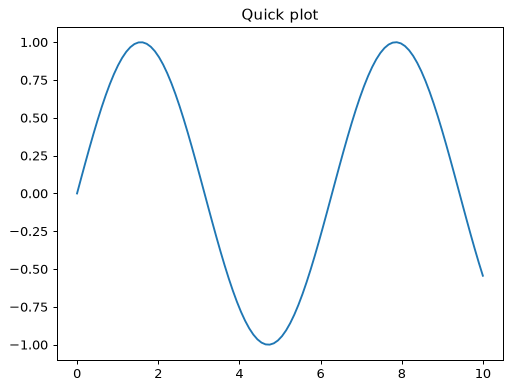

In [34]:
# Quick pyplot style
x = np.linspace(0, 10, 100)
plt.plot(x, np.sin(x))
plt.title("Quick plot")
plt.show()

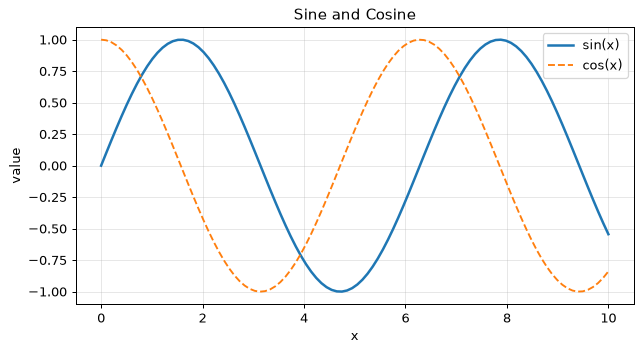

In [35]:
# Recommended object-oriented style
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x), label="sin(x)", color="tab:blue", linewidth=2)
ax.plot(x, np.cos(x), label="cos(x)", color="tab:orange", linestyle="--")
ax.set_title("Sine and Cosine")
ax.set_xlabel("x")
ax.set_ylabel("value")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 3.2 The common chart types
| Chart | Function | Use it to show |
|---|---|---|
| Line | `ax.plot` | Trends over time |
| Bar | `ax.bar` / `ax.barh` | Comparisons between categories |
| Scatter | `ax.scatter` | Relationships between two variables |
| Histogram | `ax.hist` | The distribution of one variable |
| Box plot | `ax.boxplot` | Spread and outliers |
| Pie | `ax.pie` | Parts of a whole (use sparingly) |

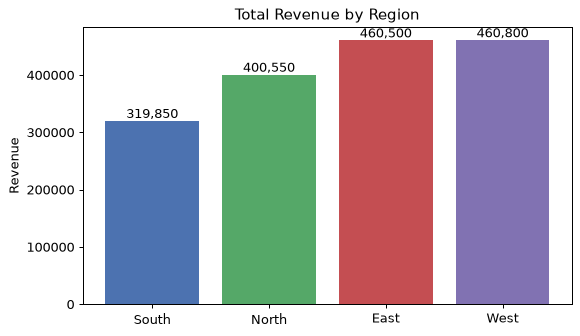

In [36]:
# Bar chart: revenue by region
rev = df.groupby("region")["revenue"].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rev.index, rev.values, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.bar_label(bars, fmt="{:,.0f}")            # value labels on top of bars
ax.set_title("Total Revenue by Region")
ax.set_ylabel("Revenue")
plt.show()

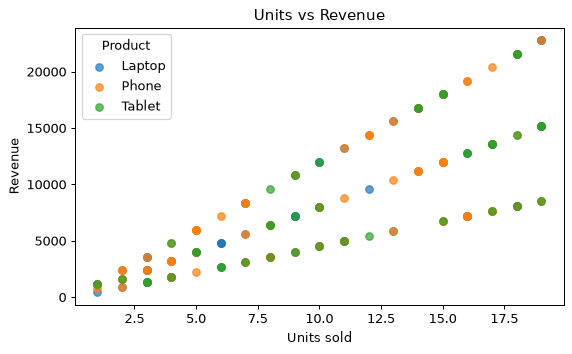

In [37]:
# Scatter plot: units vs revenue, coloured by product
fig, ax = plt.subplots(figsize=(7, 4))
for prod, grp in df.groupby("product"):
    ax.scatter(grp["units"], grp["revenue"], label=prod, alpha=0.7)
ax.set_xlabel("Units sold"); ax.set_ylabel("Revenue")
ax.set_title("Units vs Revenue")
ax.legend(title="Product")
plt.show()

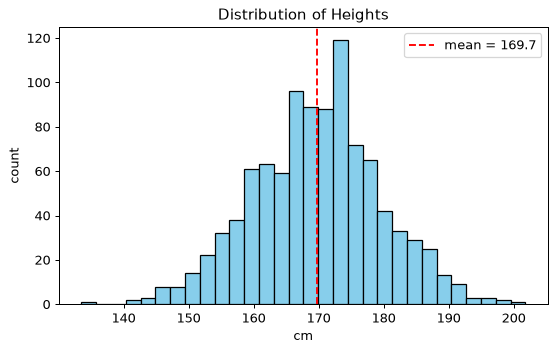

In [38]:
# Histogram: distribution of heights from the NumPy section
heights = np.random.default_rng(42).normal(170, 10, 1000)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(heights, bins=30, color="skyblue", edgecolor="black")
ax.axvline(heights.mean(), color="red", linestyle="--", label=f"mean = {heights.mean():.1f}")
ax.set_title("Distribution of Heights"); ax.set_xlabel("cm"); ax.set_ylabel("count")
ax.legend()
plt.show()

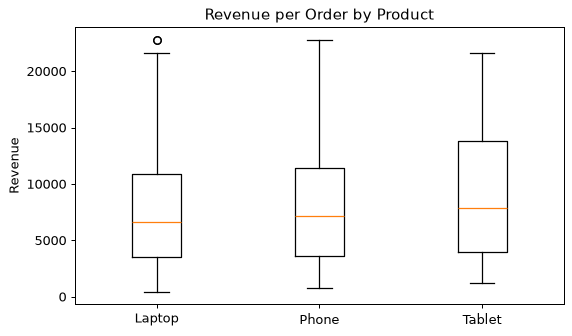

In [39]:
# Box plot: revenue spread per product
products = ["Laptop", "Phone", "Tablet"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df["product"] == p, "revenue"] for p in products])
ax.set_xticks([1, 2, 3], products)
ax.set_title("Revenue per Order by Product"); ax.set_ylabel("Revenue")
plt.show()

## 3.3 Several plots in one figure (subplots)

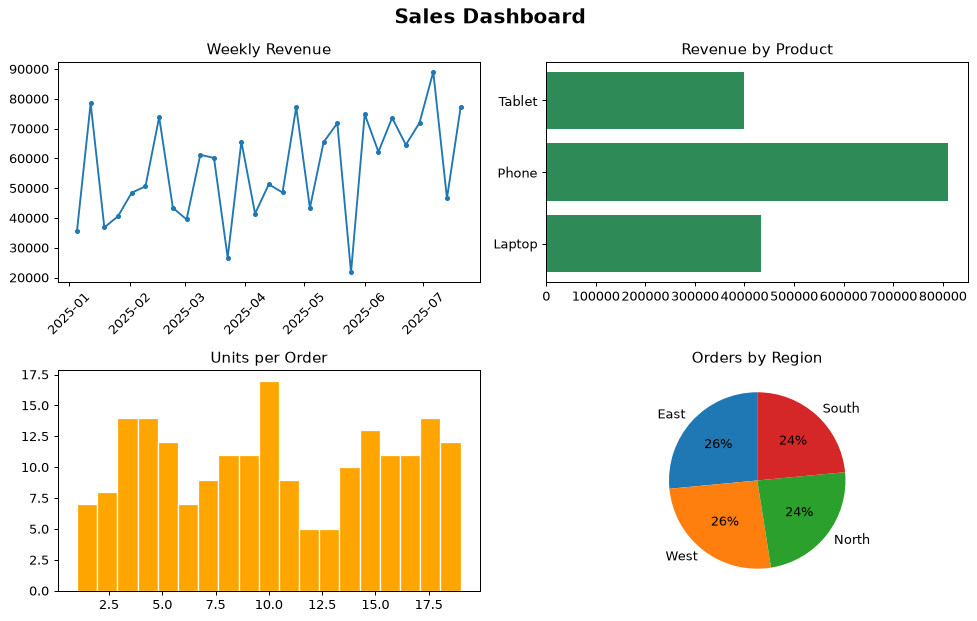

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# Top-left: line
daily = df.set_index("date")["revenue"].resample("W").sum()
axes[0, 0].plot(daily.index, daily.values, marker="o", markersize=3)
axes[0, 0].set_title("Weekly Revenue")
axes[0, 0].tick_params(axis="x", rotation=45)

# Top-right: horizontal bar
prod_rev = df.groupby("product")["revenue"].sum()
axes[0, 1].barh(prod_rev.index, prod_rev.values, color="seagreen")
axes[0, 1].set_title("Revenue by Product")

# Bottom-left: histogram
axes[1, 0].hist(df["units"], bins=19, color="orange", edgecolor="white")
axes[1, 0].set_title("Units per Order")

# Bottom-right: pie
axes[1, 1].pie(df["region"].value_counts(), labels=df["region"].value_counts().index,
               autopct="%1.0f%%", startangle=90)
axes[1, 1].set_title("Orders by Region")

fig.suptitle("Sales Dashboard", fontsize=16, fontweight="bold")
fig.tight_layout()          # prevents overlapping labels
plt.show()

## 3.4 Plotting directly from pandas
Pandas has a built-in `.plot()` method that uses matplotlib behind the scenes. It is the fastest way to explore data.

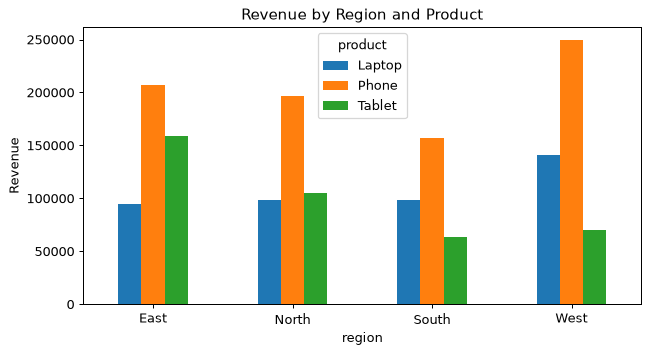

In [41]:
pivot = pd.pivot_table(df, values="revenue", index="region", columns="product", aggfunc="sum")
ax = pivot.plot(kind="bar", figsize=(8, 4), rot=0, title="Revenue by Region and Product")
ax.set_ylabel("Revenue")
plt.show()

## 3.5 Styles and saving figures

Some available styles: ['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight'] ...


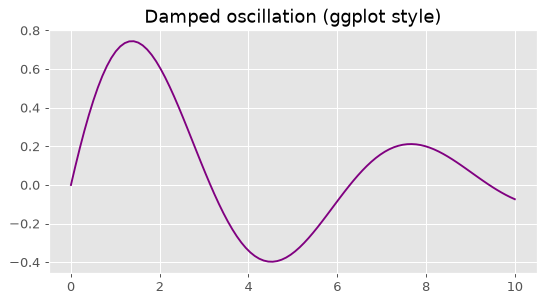

Saved figure as damped.png


In [42]:
print("Some available styles:", plt.style.available[:6], "...")

with plt.style.context("ggplot"):          # apply a style temporarily
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(x, np.sin(x) * np.exp(-x / 5), color="purple")
    ax.set_title("Damped oscillation (ggplot style)")
    fig.savefig("damped.png", dpi=150, bbox_inches="tight")   # save to file
    plt.show()
print("Saved figure as damped.png")

### Matplotlib key takeaways
- Use `fig, ax = plt.subplots()`, then call methods on `ax`.
- Always add a **title, axis labels and a legend** where they help.
- `plt.subplots(rows, cols)` builds dashboards, and `tight_layout()` keeps the labels from overlapping.
- `df.plot()` is a quick option for exploring data.

---
# Part 4: Mini project, all three together
**Question:** *How do monthly sales trend for each product, and which month was the best?*

Steps:
1. **NumPy** generates and processes the numbers.
2. **Pandas** reshapes and summarizes the data.
3. **Matplotlib** presents the answer.

In [25]:
# 1) Pandas: monthly revenue per product
df["month_num"] = df["date"].dt.to_period("M")
monthly = df.pivot_table(values="revenue", index="month_num", columns="product", aggfunc="sum")
monthly.index = monthly.index.astype(str)
monthly

product,Laptop,Phone,Tablet
month_num,,,
2025-01,40550.0,141200.0,47600.0
2025-02,23400.0,96050.0,90250.0
2025-03,76200.0,89500.0,58550.0
2025-04,51150.0,105250.0,73700.0
2025-05,83350.0,104200.0,60400.0
2025-06,103900.0,151250.0,39550.0
2025-07,53850.0,123500.0,28300.0


In [44]:
# 2) NumPy: compute growth and the best month
values = monthly.to_numpy()                       # DataFrame -> NumPy array
totals = values.sum(axis=1)                       # total per month
growth = np.diff(totals) / totals[:-1] * 100      # % month-over-month growth
best = monthly.index[np.argmax(totals)]

print("Monthly totals :", totals)
print("Growth (%)     :", growth.round(1))
print("Best month     :", best)

Monthly totals : [229350. 209700. 224250. 230100. 247950. 294700. 205650.]
Growth (%)     : [ -8.6   6.9   2.6   7.8  18.9 -30.2]
Best month     : 2025-06


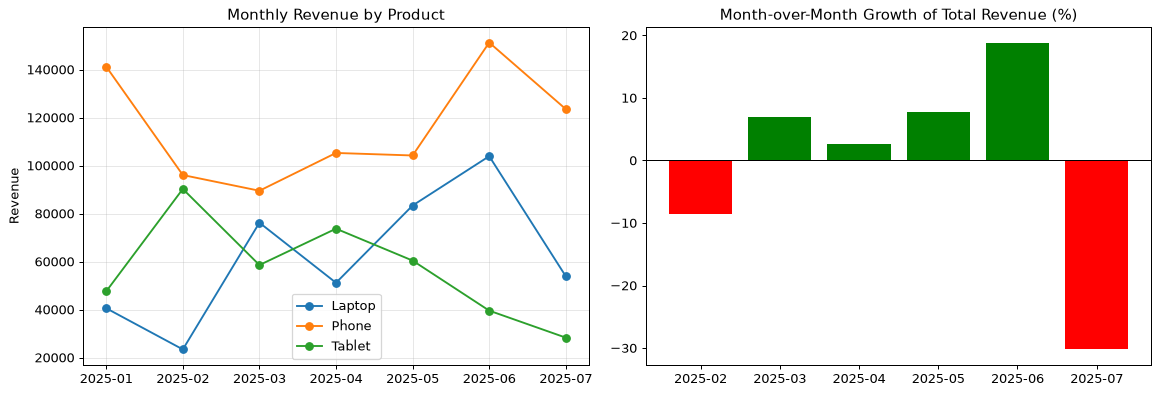

In [45]:
# 3) Matplotlib: present the result
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for col in monthly.columns:
    ax1.plot(monthly.index, monthly[col], marker="o", label=col)
ax1.set_title("Monthly Revenue by Product"); ax1.set_ylabel("Revenue"); ax1.legend()
ax1.grid(alpha=0.3)

colors = ["green" if g >= 0 else "red" for g in growth]
ax2.bar(monthly.index[1:], growth, color=colors)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Month-over-Month Growth of Total Revenue (%)")

fig.tight_layout()
plt.show()

---
# Part 5: Exercises

1. **NumPy:** Create an array of the numbers 1 to 20. Select only the numbers that are even and also greater than 10.
2. **NumPy:** Create a 4x4 array of random integers between 0 and 100. Find the maximum of each row.
3. **Pandas:** Using `df`, find the **average units per order for each region**.
4. **Pandas:** Find the 3 days with the highest revenue for the "Tablet" product.
5. **Matplotlib:** Draw a line chart of the **cumulative revenue** over time. Hint: `.cumsum()`.

In [46]:
# Your answers here

---
# Cheat sheet

### NumPy
| Task | Code |
|---|---|
| Create | `np.array([..])`, `np.zeros((r,c))`, `np.arange(a,b,step)`, `np.linspace(a,b,n)` |
| Inspect | `.shape`, `.ndim`, `.size`, `.dtype` |
| Select | `a[i]`, `a[i:j]`, `a[r, c]`, `a[a > 5]` |
| Math | `a + b`, `a * 2`, `np.sqrt(a)`, `a @ b` |
| Stats | `.sum()`, `.mean()`, `.std()`, `.max(axis=0)`, `.argmax()` |
| Reshape | `.reshape(r,c)`, `.T`, `.flatten()`, `np.concatenate` |

### Pandas
| Task | Code |
|---|---|
| Load | `pd.read_csv()`, `pd.read_excel()` |
| Inspect | `.head()`, `.info()`, `.describe()`, `.value_counts()` |
| Select | `df["c"]`, `df[["a","b"]]`, `df.loc[]`, `df.iloc[]` |
| Filter | `df[df["c"] > 5]`, `.isin()`, `.query()` |
| Missing | `.isna().sum()`, `.dropna()`, `.fillna()` |
| Summarize | `.groupby().agg()`, `pd.pivot_table()` |
| Combine | `pd.merge(a, b, on="key")`, `pd.concat([a, b])` |

### Matplotlib
| Task | Code |
|---|---|
| Set up | `fig, ax = plt.subplots(figsize=(w,h))` |
| Charts | `ax.plot`, `ax.bar`, `ax.scatter`, `ax.hist`, `ax.boxplot`, `ax.pie` |
| Labels | `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`, `ax.legend()` |
| Layout | `plt.subplots(2,2)`, `fig.tight_layout()` |
| Save | `fig.savefig("file.png", dpi=150, bbox_inches="tight")` |
